# Member 2 — Task 4: Final LightGBM Training & Export (`oof_lgbm.npy`, `test_lgbm.npy`)

**Role:** Member 2 (LightGBM Lead)  
**Branch:** `feat/m2-task4-lgbm-oof-test`  
**Primary Objective:** Train the final leak-free 5-Fold LightGBM model using the Optuna-tuned configuration from Task 3, verify multi-seed variance reduction, and export validated `oof_lgbm.npy` & `test_lgbm.npy` arrays for Phase 3 Blending with Member 3's Neural Network.

## 1. Update Shared Module (`lgbm_pipeline.py`) with Final Export & Integrity Helpers

In [1]:
%%writefile lgbm_pipeline.py
"""Shared leak-free LightGBM cross-validation, tuning, and prediction export pipeline for Member 2."""

import json
import os
import time
import warnings
from typing import Any, Iterable

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)

from data_pipeline.nn_data_pipeline import (
    CAT_COLS,
    ENGINEERED_COLS,
    ID_COL,
    N_SPLITS,
    SEED,
    TARGET_COL,
    evaluate_auprc,
)

warnings.filterwarnings("ignore", message=".*eval_set.*")

FOLD_COL = "fold"
TRAIN_LGBM_PATH = os.path.join("processed_data", "train_lgbm.parquet")
TEST_LGBM_PATH = os.path.join("processed_data", "test_lgbm.parquet")


def load_lgbm_datasets(
    train_path: str = TRAIN_LGBM_PATH,
    test_path: str = TEST_LGBM_PATH,
    verify_folds_path: str | None = "train_folds.csv",
    verify_test_raw_path: str | None = "test.csv",
) -> tuple[pd.DataFrame, pd.DataFrame, list[str], list[str]]:
    """Load Member 1's LightGBM parquet artifacts and run strict integrity checks."""
    train_df = pd.read_parquet(train_path)
    test_df = pd.read_parquet(test_path)

    excluded = {ID_COL, FOLD_COL, TARGET_COL}
    feature_cols = [c for c in train_df.columns if c not in excluded]
    cat_cols = [c for c in CAT_COLS if c in feature_cols]

    test_feature_cols = [c for c in test_df.columns if c != ID_COL]
    if feature_cols != test_feature_cols:
        raise ValueError("Train and test feature columns do not match in name or order.")

    num_tr = train_df[feature_cols].select_dtypes(include=[np.number]).to_numpy(dtype=np.float64)
    num_te = test_df[feature_cols].select_dtypes(include=[np.number]).to_numpy(dtype=np.float64)
    if np.isinf(num_tr).any() or np.isinf(num_te).any():
        raise ValueError("Infinite values detected in LightGBM numeric features.")

    if verify_folds_path and os.path.exists(verify_folds_path):
        tf = pd.read_csv(verify_folds_path, usecols=[ID_COL, FOLD_COL, TARGET_COL])
        if not np.array_equal(train_df[ID_COL].to_numpy(), tf[ID_COL].to_numpy()):
            raise ValueError("ID misalignment between train_lgbm.parquet and train_folds.csv.")
        if not np.array_equal(train_df[FOLD_COL].to_numpy(), tf[FOLD_COL].to_numpy()):
            raise ValueError("Fold misalignment between train_lgbm.parquet and train_folds.csv.")
        if not np.array_equal(
            train_df[TARGET_COL].astype(int).to_numpy(),
            tf[TARGET_COL].astype(int).to_numpy(),
        ):
            raise ValueError("Target misalignment between train_lgbm.parquet and train_folds.csv.")

    if verify_test_raw_path and os.path.exists(verify_test_raw_path):
        te_raw = pd.read_csv(verify_test_raw_path, usecols=[ID_COL])
        if not np.array_equal(test_df[ID_COL].to_numpy(), te_raw[ID_COL].to_numpy()):
            raise ValueError("ID misalignment between test_lgbm.parquet and test.csv.")

    return train_df, test_df, feature_cols, cat_cols


def compute_scale_pos_weight(y_train: np.ndarray, mode: str | float = "none") -> float:
    """Compute class weight strictly from a training fold target vector."""
    if isinstance(mode, (int, float)) and not isinstance(mode, bool):
        return float(mode)

    y_arr = np.asarray(y_train, dtype=np.int64)
    n_neg = int(np.sum(y_arr == 0))
    n_pos = int(np.sum(y_arr == 1))
    if n_pos == 0:
        raise ValueError("Training fold contains zero positive samples.")

    ratio = n_neg / n_pos
    mode_key = str(mode).lower()
    if mode_key == "none":
        return 1.0
    if mode_key == "balanced":
        return float(ratio)
    if mode_key == "sqrt":
        return float(np.sqrt(ratio))
    raise ValueError(f"Unsupported scale_pos_weight mode: {mode}")


def evaluate_predictions(
    y_true: np.ndarray,
    y_pred_proba: np.ndarray,
    verbose: bool = False,
) -> dict[str, Any]:
    """Evaluate continuous fraud probabilities using AUPRC (primary) and auxiliary metrics."""
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_pred_proba, dtype=np.float64)

    auprc = evaluate_auprc(y_true_arr, y_prob_arr)
    roc_auc = float(roc_auc_score(y_true_arr, y_prob_arr))

    precisions, recalls, thresholds = precision_recall_curve(y_true_arr, y_prob_arr)
    f1_scores = np.divide(
        2.0 * precisions * recalls,
        precisions + recalls,
        out=np.zeros_like(precisions),
        where=(precisions + recalls) > 0,
    )
    best_idx = int(np.argmax(f1_scores))
    best_threshold = float(thresholds[best_idx]) if best_idx < len(thresholds) else 0.5
    best_f1 = float(f1_scores[best_idx])
    best_precision = float(precisions[best_idx])
    best_recall = float(recalls[best_idx])
    f1_at_05 = float(f1_score(y_true_arr, (y_prob_arr >= 0.5).astype(int), zero_division=0))
    cm = confusion_matrix(y_true_arr, (y_prob_arr >= best_threshold).astype(int))

    if verbose:
        print("=" * 56)
        print(f"OOF AUPRC (Primary) : {auprc:.6f}")
        print(f"OOF ROC-AUC         : {roc_auc:.6f}")
        print(f"F1 @ 0.50           : {f1_at_05:.6f}")
        print(
            f"Best F1             : {best_f1:.6f} @ threshold={best_threshold:.4f} "
            f"(P={best_precision:.4f}, R={best_recall:.4f})"
        )
        print(f"Confusion Matrix (Best Thresh):\n{cm}")
        print("=" * 56)

    return {
        "auprc": auprc,
        "roc_auc": roc_auc,
        "f1_at_05": f1_at_05,
        "best_f1": best_f1,
        "best_threshold": best_threshold,
        "best_precision": best_precision,
        "best_recall": best_recall,
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    }


def get_default_lgbm_params(seed: int = SEED) -> dict[str, Any]:
    """Return clean baseline LightGBM hyperparameters for binary fraud detection."""
    return {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "learning_rate": 0.05,
        "n_estimators": 2000,
        "num_leaves": 31,
        "max_depth": -1,
        "subsample": 1.0,
        "subsample_freq": 0,
        "colsample_bytree": 1.0,
        "min_child_samples": 20,
        "reg_alpha": 0.0,
        "reg_lambda": 0.0,
        "random_state": seed,
        "n_jobs": -1,
        "verbose": -1,
    }


def load_best_lgbm_params(path: str = "best_lgbm_params.json") -> dict[str, Any]:
    """Load Optuna-tuned LightGBM hyperparameter dictionary exported by Task 3."""
    with open(path, "r", encoding="utf-8") as f:
        payload = json.load(f)
    return dict(payload["params"])


def verify_exported_predictions(
    oof_path: str,
    test_path: str,
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    expected_auprc: float | None = None,
) -> dict[str, Any]:
    """Reload exported .npy files from disk and enforce strict shape, range, and metric checks."""
    oof_arr = np.load(oof_path)
    test_arr = np.load(test_path)

    if oof_arr.ndim != 1 or len(oof_arr) != len(train_df):
        raise ValueError(f"Invalid oof shape {oof_arr.shape}; expected ({len(train_df)},).")
    if test_arr.ndim != 1 or len(test_arr) != len(test_df):
        raise ValueError(f"Invalid test shape {test_arr.shape}; expected ({len(test_df)},).")

    for name, arr in [("oof_lgbm", oof_arr), ("test_lgbm", test_arr)]:
        if np.isnan(arr).any() or np.isinf(arr).any():
            raise ValueError(f"{name} contains NaN or Inf values.")
        if float(arr.min()) < 0.0 or float(arr.max()) > 1.0:
            raise ValueError(f"{name} values out of [0, 1]: min={arr.min()}, max={arr.max()}.")

    reloaded_auprc = evaluate_auprc(train_df[TARGET_COL].to_numpy(), oof_arr)
    if expected_auprc is not None and abs(reloaded_auprc - expected_auprc) > 1e-10:
        raise ValueError(f"Reloaded AUPRC {reloaded_auprc} != expected {expected_auprc}.")

    return {
        "oof_shape": oof_arr.shape,
        "test_shape": test_arr.shape,
        "oof_dtype": str(oof_arr.dtype),
        "test_dtype": str(test_arr.dtype),
        "reloaded_oof_auprc": reloaded_auprc,
        "oof_mean": float(oof_arr.mean()),
        "test_mean": float(test_arr.mean()),
        "oof_p99": float(np.percentile(oof_arr, 99)),
        "test_p99": float(np.percentile(test_arr, 99)),
    }


def run_lgbm_cv(
    train_df: pd.DataFrame,
    feature_cols: list[str],
    params: dict[str, Any] | None = None,
    test_df: pd.DataFrame | None = None,
    cat_cols: list[str] | None = None,
    spw_mode: str | float | None = None,
    stopping_rounds: int = 100,
    seeds: Iterable[int] = (SEED,),
    verbose: bool = True,
) -> dict[str, Any]:
    """Run leak-free Stratified 5-Fold LightGBM CV using train_df['fold']."""
    start_time = time.perf_counter()
    seeds_list = list(seeds)
    base_params = get_default_lgbm_params()
    if params is not None:
        base_params.update(params)

    if cat_cols is None:
        cat_cols = [c for c in CAT_COLS if c in feature_cols]

    X_all = train_df[feature_cols]
    y_all = train_df[TARGET_COL].astype(np.int64).to_numpy()
    folds = train_df[FOLD_COL].to_numpy()
    X_test = test_df[feature_cols] if test_df is not None else None

    oof_preds = np.zeros(len(train_df), dtype=np.float64)
    test_preds = np.zeros(len(test_df), dtype=np.float64) if test_df is not None else None

    fold_auprcs: list[float] = []
    best_iterations: list[int] = []
    gain_importances = np.zeros(len(feature_cols), dtype=np.float64)
    split_importances = np.zeros(len(feature_cols), dtype=np.float64)

    for fold in range(N_SPLITS):
        tr_mask = folds != fold
        va_mask = folds == fold

        X_tr, y_tr = X_all.loc[tr_mask], y_all[tr_mask]
        X_va, y_va = X_all.loc[va_mask], y_all[va_mask]

        fold_val_preds = np.zeros(int(va_mask.sum()), dtype=np.float64)
        fold_test_preds = np.zeros(len(test_df), dtype=np.float64) if X_test is not None else None
        fold_iters: list[int] = []

        for seed in seeds_list:
            fold_params = dict(base_params)
            fold_params["random_state"] = int(seed)
            fold_params["bagging_seed"] = int(seed)
            fold_params["feature_fraction_seed"] = int(seed)

            if spw_mode is not None:
                fold_params.pop("is_unbalance", None)
                fold_params["scale_pos_weight"] = compute_scale_pos_weight(y_tr, mode=spw_mode)

            model = lgb.LGBMClassifier(**fold_params)
            callbacks = [lgb.early_stopping(stopping_rounds=stopping_rounds, verbose=False)]

            model.fit(
                X_tr,
                y_tr,
                eval_set=[(X_va, y_va)],
                eval_metric="average_precision",
                categorical_feature=cat_cols if cat_cols else "auto",
                callbacks=callbacks,
            )

            best_iter = int(model.best_iteration_ or fold_params.get("n_estimators", 2000))
            fold_iters.append(best_iter)

            fold_val_preds += model.predict_proba(X_va, num_iteration=best_iter)[:, 1] / len(seeds_list)
            if X_test is not None and fold_test_preds is not None:
                fold_test_preds += model.predict_proba(X_test, num_iteration=best_iter)[:, 1] / len(seeds_list)

            gain_importances += model.booster_.feature_importance(importance_type="gain") / (N_SPLITS * len(seeds_list))
            split_importances += model.booster_.feature_importance(importance_type="split") / (N_SPLITS * len(seeds_list))

        oof_preds[va_mask] = fold_val_preds
        if test_preds is not None and fold_test_preds is not None:
            test_preds += fold_test_preds / N_SPLITS

        fold_auprc = evaluate_auprc(y_va, fold_val_preds)
        fold_auprcs.append(fold_auprc)
        avg_iter = int(round(float(np.mean(fold_iters))))
        best_iterations.append(avg_iter)

        if verbose:
            print(f"Fold {fold} | AUPRC: {fold_auprc:.6f} | Best Iter: {avg_iter}")

    elapsed = time.perf_counter() - start_time
    overall = evaluate_predictions(y_all, oof_preds, verbose=verbose)
    mean_auprc = float(np.mean(fold_auprcs))
    std_auprc = float(np.std(fold_auprcs))

    if verbose:
        print(
            f"Mean 5-Fold AUPRC: {mean_auprc:.6f} +/- {std_auprc:.6f} "
            f"| Avg Best Iter: {np.mean(best_iterations):.1f} | Time: {elapsed:.1f}s"
        )

    fi_df = pd.DataFrame(
        {
            "feature": feature_cols,
            "gain": gain_importances,
            "split": split_importances,
            "is_engineered": [c in ENGINEERED_COLS for c in feature_cols],
        }
    ).sort_values("gain", ascending=False).reset_index(drop=True)
    fi_df["gain_pct"] = 100.0 * fi_df["gain"] / max(fi_df["gain"].sum(), 1e-12)

    return {
        "oof_preds": oof_preds,
        "test_preds": test_preds,
        "fold_auprcs": fold_auprcs,
        "mean_auprc": mean_auprc,
        "std_auprc": std_auprc,
        "metrics": overall,
        "best_iterations": best_iterations,
        "feature_importance_df": fi_df,
        "train_time_sec": float(elapsed),
    }

Overwriting lgbm_pipeline.py


## 2. Load Datasets & Best Optuna Hyperparameters

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from lgbm.lgbm_pipeline import (
    TARGET_COL,
    load_best_lgbm_params,
    load_lgbm_datasets,
    run_lgbm_cv,
    verify_exported_predictions,
)

sns.set_theme(style="whitegrid")

train_df, test_df, feature_cols, cat_cols = load_lgbm_datasets()
best_params = load_best_lgbm_params("best_lgbm_params.json")

print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape} | Features: {len(feature_cols)}")
print("Loaded Optuna Best Hyperparameters:")
print(json.dumps(best_params, indent=2))

Train shape: (699960, 38) | Test shape: (299984, 36) | Features: 35
Loaded Optuna Best Hyperparameters:
{
  "objective": "binary",
  "metric": "average_precision",
  "boosting_type": "gbdt",
  "learning_rate": 0.028804556398208715,
  "n_estimators": 4000,
  "num_leaves": 11,
  "max_depth": 4,
  "colsample_bytree": 0.4615970860753574,
  "subsample": 0.9581351083206087,
  "subsample_freq": 1,
  "min_child_samples": 172,
  "reg_alpha": 0.3089016400296857,
  "reg_lambda": 18.30744086412154,
  "scale_pos_weight": 3.359272372588889,
  "random_state": 42,
  "n_jobs": -1,
  "verbose": -1
}


## 3. Single-Seed vs. 3-Seed Bagged 5-Fold Training & Test Inference

We evaluate both single-seed (`[42]`) and 3-seed bagging (`[42, 2024, 2026]`) across all 5 Stratified folds, selecting the higher-AUPRC predictor to export `oof_lgbm.npy` and `test_lgbm.npy`.

In [3]:
print(">>> Model A: Tuned LightGBM (Single Seed = [42])")
res_single = run_lgbm_cv(
    train_df=train_df,
    feature_cols=feature_cols,
    params=best_params,
    test_df=test_df,
    cat_cols=cat_cols,
    stopping_rounds=100,
    seeds=(42,),
    verbose=True,
)

print("\n>>> Model B: Tuned LightGBM (3-Seed Bagging = [42, 2024, 2026])")
res_bagged = run_lgbm_cv(
    train_df=train_df,
    feature_cols=feature_cols,
    params=best_params,
    test_df=test_df,
    cat_cols=cat_cols,
    stopping_rounds=100,
    seeds=(42, 2024, 2026),
    verbose=True,
)

if res_bagged["metrics"]["auprc"] >= res_single["metrics"]["auprc"]:
    final_res = res_bagged
    chosen_label = "3-Seed Bagged Tuned LightGBM ([42, 2024, 2026])"
    chosen_seeds = [42, 2024, 2026]
else:
    final_res = res_single
    chosen_label = "Single-Seed Tuned LightGBM ([42])"
    chosen_seeds = [42]

print(f"\nSelected Final Model -> {chosen_label} | OOF AUPRC = {final_res['metrics']['auprc']:.6f}")

>>> Model A: Tuned LightGBM (Single Seed = [42])
Fold 0 | AUPRC: 0.497926 | Best Iter: 1249
Fold 1 | AUPRC: 0.520518 | Best Iter: 1924
Fold 2 | AUPRC: 0.532373 | Best Iter: 1856
Fold 3 | AUPRC: 0.517486 | Best Iter: 1527
Fold 4 | AUPRC: 0.501339 | Best Iter: 2098
OOF AUPRC (Primary) : 0.513629
OOF ROC-AUC         : 0.947215
F1 @ 0.50           : 0.501455
Best F1             : 0.502849 @ threshold=0.4855 (P=0.5156, R=0.4907)
Confusion Matrix (Best Thresh):
[[682882   5389]
 [  5953   5736]]
Mean 5-Fold AUPRC: 0.513929 +/- 0.012735 | Avg Best Iter: 1730.8 | Time: 266.0s

>>> Model B: Tuned LightGBM (3-Seed Bagging = [42, 2024, 2026])
Fold 0 | AUPRC: 0.499601 | Best Iter: 1164
Fold 1 | AUPRC: 0.521312 | Best Iter: 1787
Fold 2 | AUPRC: 0.533050 | Best Iter: 1579
Fold 3 | AUPRC: 0.518428 | Best Iter: 1883
Fold 4 | AUPRC: 0.502005 | Best Iter: 1911
OOF AUPRC (Primary) : 0.514561
OOF ROC-AUC         : 0.947308
F1 @ 0.50           : 0.502678
Best F1             : 0.505128 @ threshold=0.5202 (P

## 4. Export `oof_lgbm.npy` & `test_lgbm.npy` and Run Strict Integrity Checks

In [4]:
OOF_PATH = "oof_lgbm.npy"
TEST_PATH = "test_lgbm.npy"

np.save(OOF_PATH, final_res["oof_preds"].astype(np.float64))
np.save(TEST_PATH, final_res["test_preds"].astype(np.float64))

check_report = verify_exported_predictions(
    oof_path=OOF_PATH,
    test_path=TEST_PATH,
    train_df=train_df,
    test_df=test_df,
    expected_auprc=final_res["metrics"]["auprc"],
)

print("Integrity Check Passed Successfully:")
print(json.dumps(check_report, indent=2))

# Summary statistics table comparing OOF and Test probability distributions
oof_arr = np.load(OOF_PATH)
test_arr = np.load(TEST_PATH)

dist_df = pd.DataFrame(
    {
        "Split": ["OOF Train (699,960)", "Test (299,984)"],
        "Min": [oof_arr.min(), test_arr.min()],
        "Mean": [oof_arr.mean(), test_arr.mean()],
        "Std": [oof_arr.std(), test_arr.std()],
        "Median_P50": [np.percentile(oof_arr, 50), np.percentile(test_arr, 50)],
        "P90": [np.percentile(oof_arr, 90), np.percentile(test_arr, 90)],
        "P99": [np.percentile(oof_arr, 99), np.percentile(test_arr, 99)],
        "Max": [oof_arr.max(), test_arr.max()],
        "Frac_ge_0.50": [(oof_arr >= 0.5).mean(), (test_arr >= 0.5).mean()],
    }
)
display(dist_df)

final_summary = {
    "model": chosen_label,
    "seeds": chosen_seeds,
    "oof_path": OOF_PATH,
    "test_path": TEST_PATH,
    "oof_shape": list(oof_arr.shape),
    "test_shape": list(test_arr.shape),
    "oof_auprc": float(final_res["metrics"]["auprc"]),
    "mean_fold_auprc": float(final_res["mean_auprc"]),
    "std_fold_auprc": float(final_res["std_auprc"]),
    "oof_roc_auc": float(final_res["metrics"]["roc_auc"]),
    "best_f1": float(final_res["metrics"]["best_f1"]),
    "best_threshold": float(final_res["metrics"]["best_threshold"]),
    "fold_auprcs": [float(x) for x in final_res["fold_auprcs"]],
    "best_iterations": [int(x) for x in final_res["best_iterations"]],
}
with open("lgbm_final_metadata.json", "w", encoding="utf-8") as f:
    json.dump(final_summary, f, indent=2)

Integrity Check Passed Successfully:
{
  "oof_shape": [
    699960
  ],
  "test_shape": [
    299984
  ],
  "oof_dtype": "float64",
  "test_dtype": "float64",
  "reloaded_oof_auprc": 0.5145607477360743,
  "oof_mean": 0.035895677577251935,
  "test_mean": 0.03575725166955959,
  "oof_p99": 0.6413176701064335,
  "test_p99": 0.6425962412723154
}


,Split,Min,Mean,Std,Median_P50,P90,P99,Max,Frac_ge_0.50
0,"OOF Train (699,960)",0.000001,0.035896,0.106905,0.005231,0.073451,0.641318,0.999045,0.015308
1,"Test (299,984)",0.000002,0.035757,0.106765,0.005276,0.072690,0.642596,0.998594,0.015334


## 5. Final Diagnostics: OOF vs. Test Distribution, PR Curve & Feature Importance

Coreach.ai Comment -> LGBM Final (3-Seed Bagged Tuned LightGBM ([42, 2024, 2026]), OOF & Test .npy Exported) | CV OOF AUPRC: 0.5146 (Mean Fold: 0.5149 +/- 0.0125)


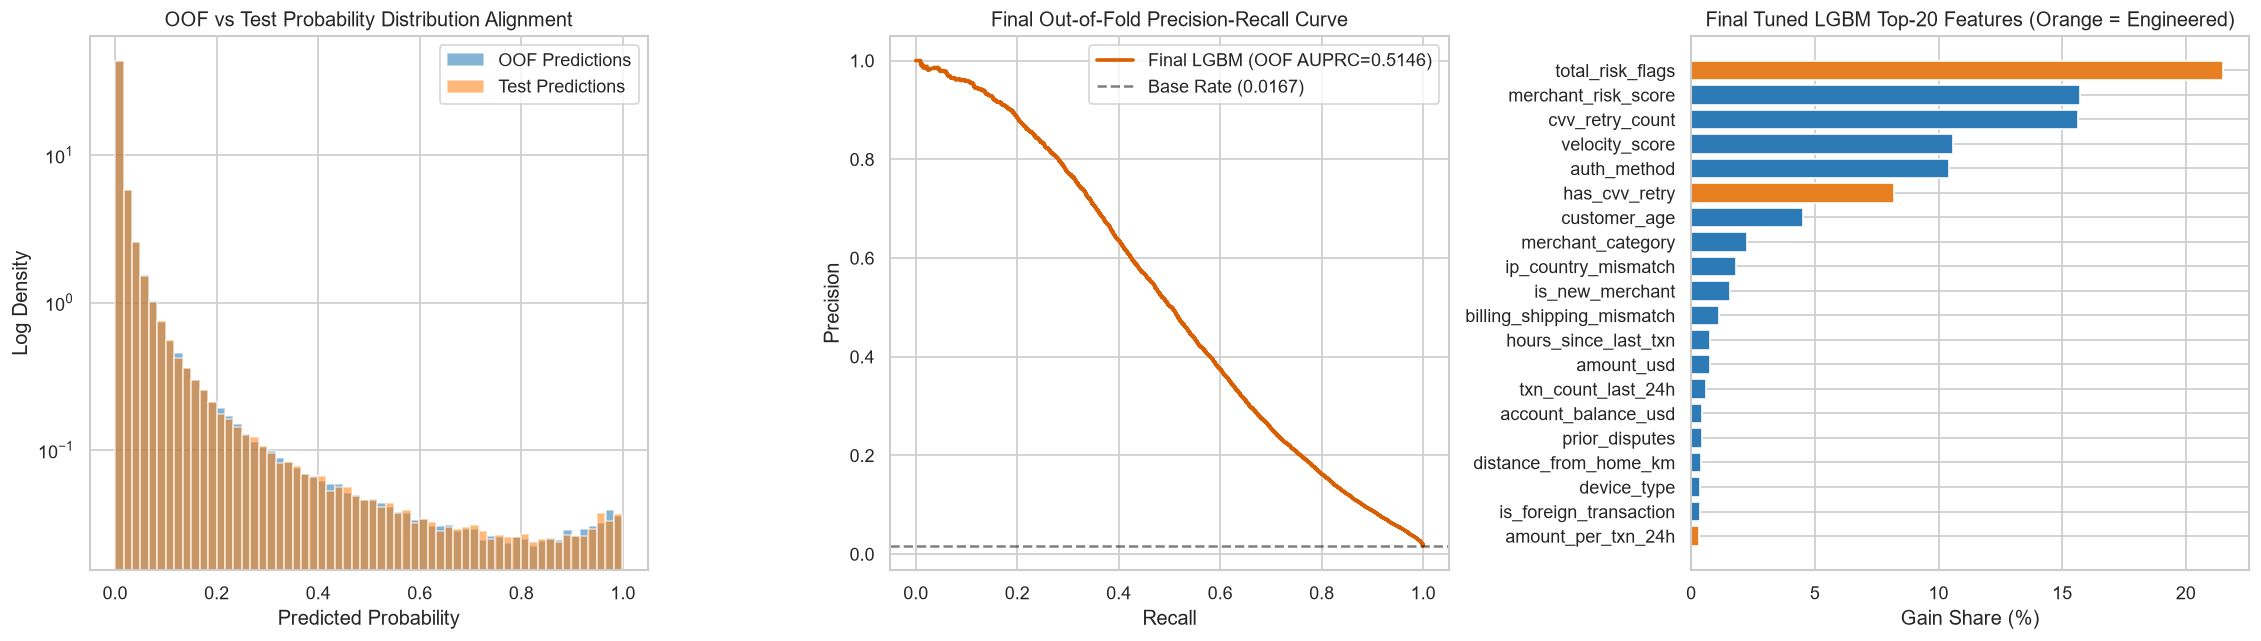

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# Plot 1: Log-scale Probability Distribution Alignment (OOF vs Test)
axes[0].hist(oof_arr, bins=60, density=True, alpha=0.55, label="OOF Predictions", color="#1f77b4", log=True)
axes[0].hist(test_arr, bins=60, density=True, alpha=0.55, label="Test Predictions", color="#ff7f0e", log=True)
axes[0].set_xlabel("Predicted Probability")
axes[0].set_ylabel("Log Density")
axes[0].set_title("OOF vs Test Probability Distribution Alignment")
axes[0].legend()

# Plot 2: Final Precision-Recall Curve
y_true = train_df[TARGET_COL].to_numpy()
p, r, _ = precision_recall_curve(y_true, oof_arr)
axes[1].plot(r, p, color="#d95f02", linewidth=2.2, label=f"Final LGBM (OOF AUPRC={final_res['metrics']['auprc']:.4f})")
axes[1].axhline(y_true.mean(), linestyle="--", color="black", alpha=0.5, label=f"Base Rate ({y_true.mean():.4f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Final Out-of-Fold Precision-Recall Curve")
axes[1].legend(loc="upper right")

# Plot 3: Final Top-20 Feature Importance
fi_df = final_res["feature_importance_df"]
top20 = fi_df.head(20).iloc[::-1]
colors = ["#e67e22" if eng else "#2c7bb6" for eng in top20["is_engineered"]]
axes[2].barh(top20["feature"], top20["gain_pct"], color=colors)
axes[2].set_xlabel("Gain Share (%)")
axes[2].set_title("Final Tuned LGBM Top-20 Features (Orange = Engineered)")

plt.tight_layout()
plt.show()

print(
    f"Coreach.ai Comment -> LGBM Final ({chosen_label}, OOF & Test .npy Exported) "
    f"| CV OOF AUPRC: {final_res['metrics']['auprc']:.4f} "
    f"(Mean Fold: {final_res['mean_auprc']:.4f} +/- {final_res['std_auprc']:.4f})"
)